In [1]:
#importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Dataset Description**

Load and Incept the Dataset

In [3]:
# Load dataset
from google.colab import files
#uploaded = files.upload()
df = pd.read_csv('/content/drive/MyDrive/422/Tree_Sterility_Dataset.csv')

# View dataset structure
print("Shape of dataset:", df.shape)
print("\nColumn information:")
print(df.info())
print("\nFirst five rows:")
print(df.head())

Shape of dataset: (2783, 24)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2783 entries, 0 to 2782
Data columns (total 24 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   No           2783 non-null   int64  
 1   Plot         2783 non-null   int64  
 2   Subplot      2783 non-null   object 
 3   Species      2783 non-null   object 
 4   Light_ISF    2783 non-null   float64
 5   Light_Cat    2783 non-null   object 
 6   Core         2783 non-null   int64  
 7   Soil         2783 non-null   object 
 8   Adult        2783 non-null   object 
 9   Sterile      2783 non-null   object 
 10  Conspecific  2783 non-null   object 
 11  Myco         2783 non-null   object 
 12  SoilMyco     2783 non-null   object 
 13  PlantDate    2783 non-null   object 
 14  AMF          2783 non-null   float64
 15  EMF          1283 non-null   float64
 16  Phenolics    2783 non-null   float64
 17  Lignin       2783 non-null   float64
 18

Sterile
Non-Sterile    2360
Sterile         423
Name: count, dtype: int64


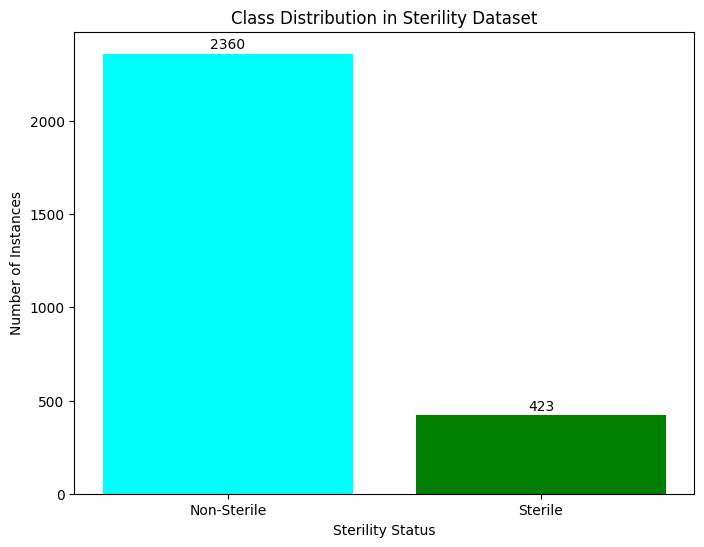

In [4]:
sterile_counts = df['Sterile'].value_counts()
print(sterile_counts)
import matplotlib.pyplot as plt

# Data
classes = ['Non-Sterile', 'Sterile']
counts = [2360, 423]

# Create bar chart
plt.figure(figsize=(8, 6))
bars=plt.bar(classes, counts, color=['cyan', 'green'])
plt.title('Class Distribution in Sterility Dataset')
plt.xlabel('Sterility Status')
plt.ylabel('Number of Instances')

# Add count labels on top of bars
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
             str(count), ha='center', va='bottom')
plt.show()

Number of Features and Data Points

In [5]:
# Number of rows and columns
print("Number of data points (rows):", df.shape[0])
print("Number of features (columns including target):", df.shape[1])

Number of data points (rows): 2783
Number of features (columns including target): 24


Classification or Regression

In [6]:
# Explicitly define the target column based on the problem
target_col = 'Sterile'

# Show unique values
print(f"Target column selected: {target_col}")
print("Unique values in the target column:")
print(df[target_col].unique())

# Check data type
print("Data type of target column:", df[target_col].dtype)

# Classification or regression check
if df[target_col].dtype == 'object' or df[target_col].nunique() <= 10:
    print(" This is a Classification Problem.")
else:
    print(" This appears to be a Regression Problem.")

Target column selected: Sterile
Unique values in the target column:
['Non-Sterile' 'Sterile']
Data type of target column: object
 This is a Classification Problem.


Feature Types: Quantitative vs Categorical

In [7]:
# Separate quantitative and categorical features
quantitative = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Quantitative features:", quantitative)
print("Categorical features:", categorical)


Quantitative features: ['No', 'Plot', 'Light_ISF', 'Core', 'AMF', 'EMF', 'Phenolics', 'Lignin', 'NSC', 'Census', 'Time', 'Event']
Categorical features: ['Subplot', 'Species', 'Light_Cat', 'Soil', 'Adult', 'Sterile', 'Conspecific', 'Myco', 'SoilMyco', 'PlantDate', 'Harvest', 'Alive']


In [ ]:
categorical_data=df.select_dtypes(include= 'object')
categorical_data.describe().T

,count,unique,top,freq
Subplot,2783,5,A,701
Species,2783,4,Acer saccharum,751
Light_Cat,2783,3,Med,1474
Soil,2783,7,Sterile,423
Adult,2783,36,I,90
Sterile,2783,2,Non-Sterile,2360
Conspecific,2783,3,Heterospecific,1974
Myco,2783,2,AMF,1500
SoilMyco,2783,3,AMF,1186
PlantDate,2783,19,6/7/18,340


In [8]:
##Selecting numerical features
numerical_data = df.select_dtypes(include='number')
numerical_data.describe().T


,count,mean,std,min,25%,50%,75%,max
No,2783.0,3914.513834,2253.515063,3.000,1971.000,3932.000,5879.000,7772.000
Plot,2783.0,9.561624,5.203659,1.000,5.000,10.000,14.000,18.000
Light_ISF,2783.0,0.085707,0.025638,0.032,0.066,0.082,0.100,0.161
Core,2783.0,2016.648940,0.477387,2016.000,2016.000,2017.000,2017.000,2017.000
AMF,2783.0,20.553069,12.309587,0.000,13.400,18.000,24.445,100.000
EMF,1283.0,26.476750,16.636890,0.000,13.780,27.720,35.710,87.500
Phenolics,2783.0,1.933105,1.969842,-1.350,0.170,0.750,3.780,6.100
Lignin,2783.0,15.759792,6.779607,2.230,10.355,14.040,21.115,32.770
NSC,2783.0,14.219641,4.298271,4.300,11.605,12.660,17.275,29.450
Census,2783.0,15.282070,9.166555,4.000,7.000,13.000,18.000,33.000


In [ ]:
numerical_data.var()

,0
No,5.078330e+06
Plot,2.707807e+01
Light_ISF,6.572914e-04
Core,2.278988e-01
AMF,1.515259e+02
EMF,2.767861e+02
Phenolics,3.880277e+00
Lignin,4.596307e+01
NSC,1.847513e+01
Census,8.402573e+01


In [ ]:
numerical_data.skew()

,0
No,-0.013436
Plot,-0.012063
Light_ISF,0.658495
Core,-0.624428
AMF,1.530073
EMF,0.504768
Phenolics,0.325592
Lignin,0.141701
NSC,0.569887
Census,1.033268


Correlation Analysis

Imbalanced Dataset Check

In [ ]:
# Count class distribution
class_counts = df['Sterile'].value_counts().reset_index()
class_counts.columns = ['Sterile', 'Count']
class_counts['Sterile'] = class_counts['Sterile'].map({0: 'Non-Sterile (0)', 1: 'Sterile (1)'})

# Plot bar chart
plt.figure(figsize=(6, 6))
sns.barplot(data=class_counts, x='Sterile', y='Count', hue='Sterile',
            palette=['skyblue', 'salmon'], legend=False)

# Add value labels on bars
for i, row in class_counts.iterrows():
    plt.text(i, row['Count'] + 5, str(row['Count']), ha='center', fontsize=11)

plt.title("Class Distribution")
plt.xlabel("Sterility Status")
plt.ylabel("Number of Trees")
plt.tight_layout()
plt.show()

# Print class percentages
total = class_counts['Count'].sum()
print("Class distribution (%):")
for i, row in class_counts.iterrows():
    percent = round((row['Count'] / total) * 100, 2)
    print(f"{row['Sterile']}: {percent}%")


<ipython-input-82-52040072619c>:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.barplot(data=class_counts, x='Sterile', y='Count', hue='Sterile',
<ipython-input-82-52040072619c>:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


Class distribution (%):
nan: 84.8%
nan: 15.2%


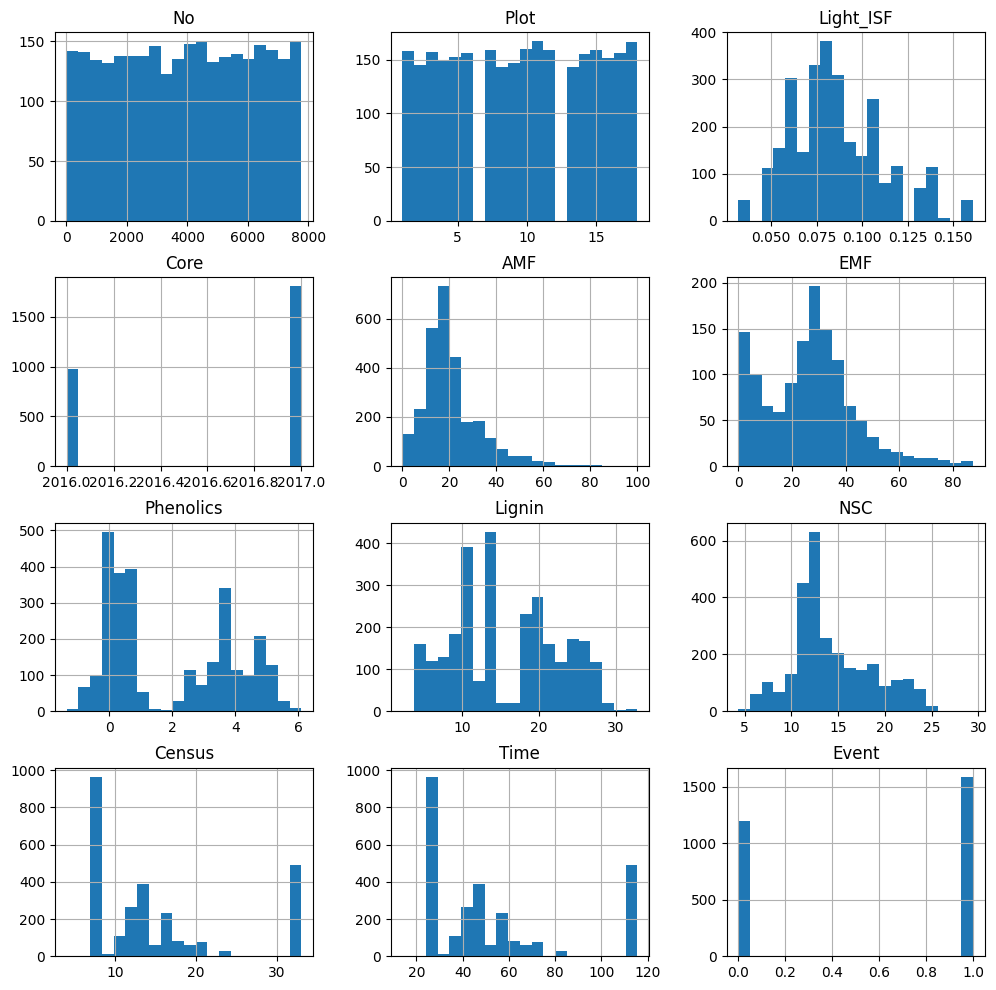

In [ ]:
df.hist(figsize=(12,12),bins=20)
plt.show()

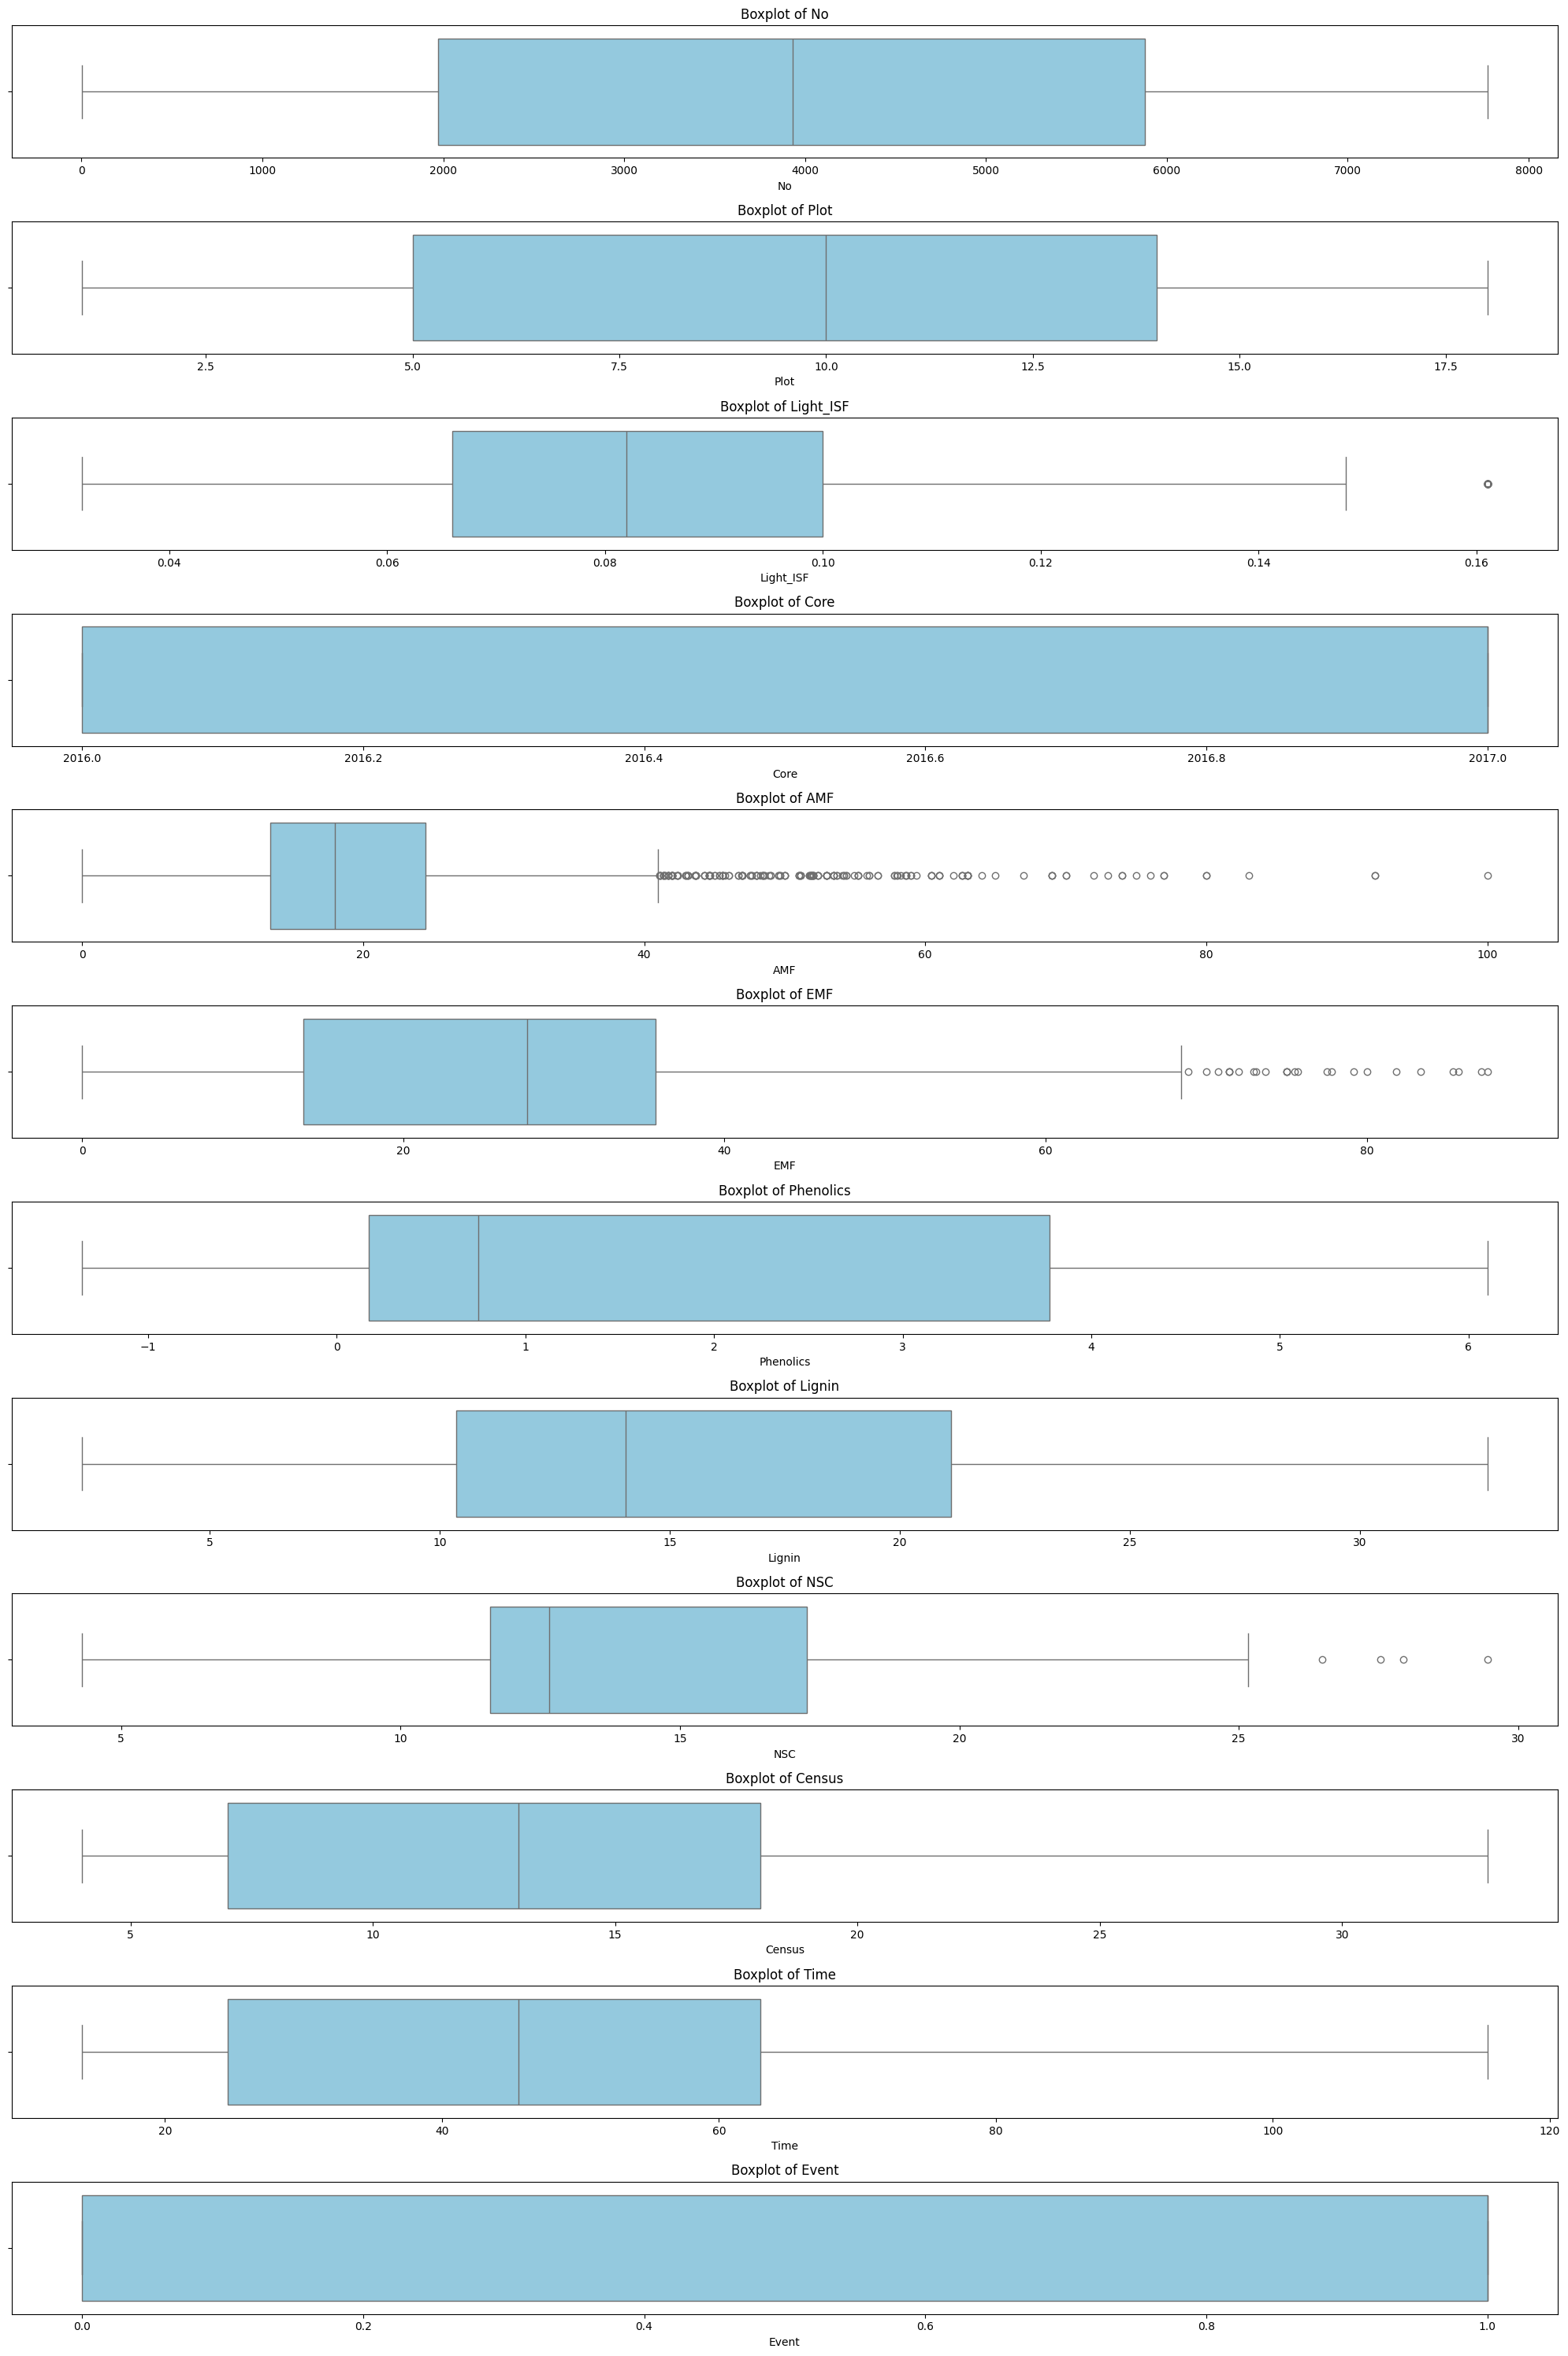

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [ ]:
df.isnull().sum()

,0
No,0
Plot,0
Subplot,0
Species,0
Light_ISF,0
Light_Cat,0
Core,0
Soil,0
Adult,0
Sterile,0


Subplot         5
Species         4
Light_Cat       3
Soil            7
Adult          36
Sterile         2
Conspecific     3
Myco            2
SoilMyco        3
PlantDate      19
Harvest         1
Alive           1
dtype: int64


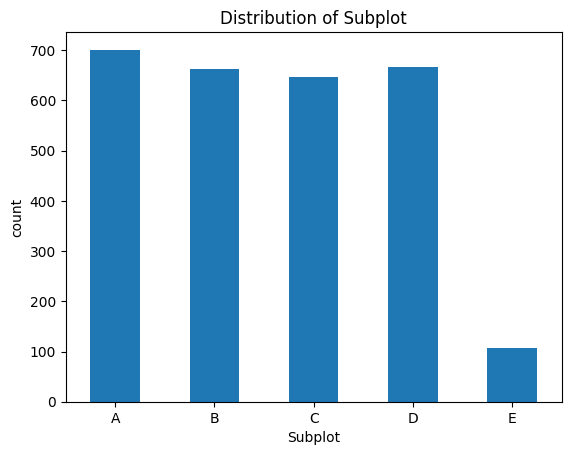

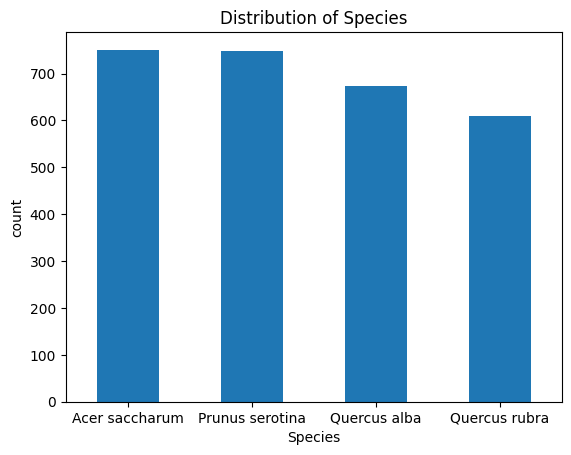

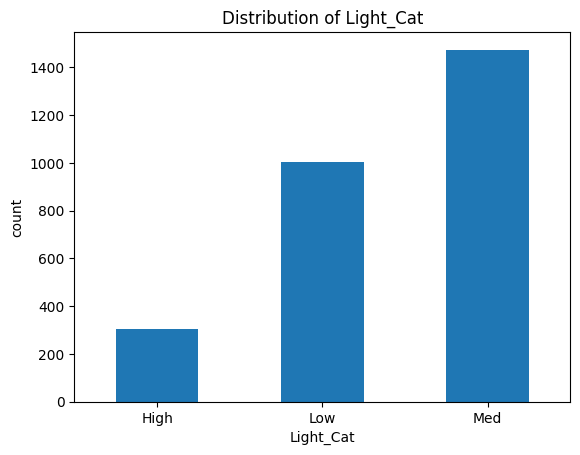

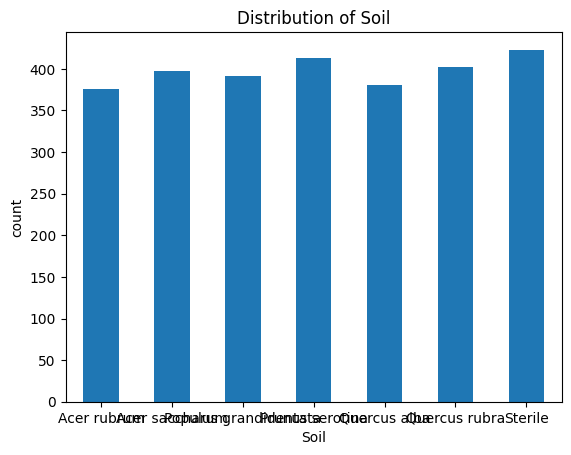

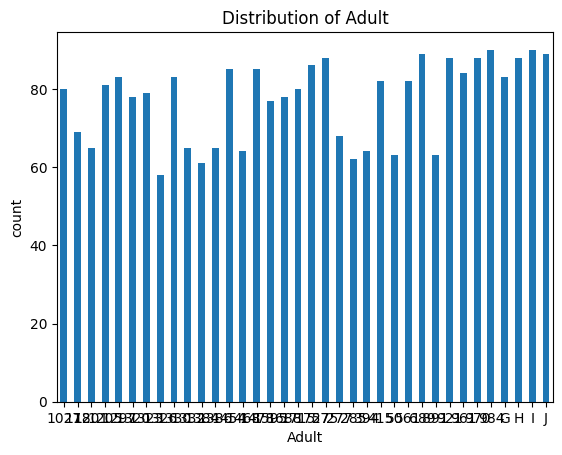

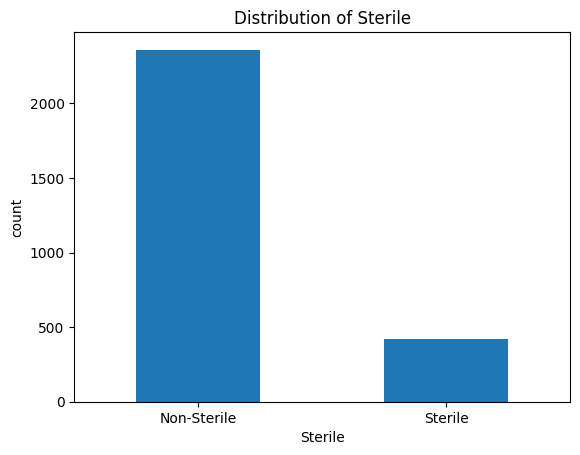

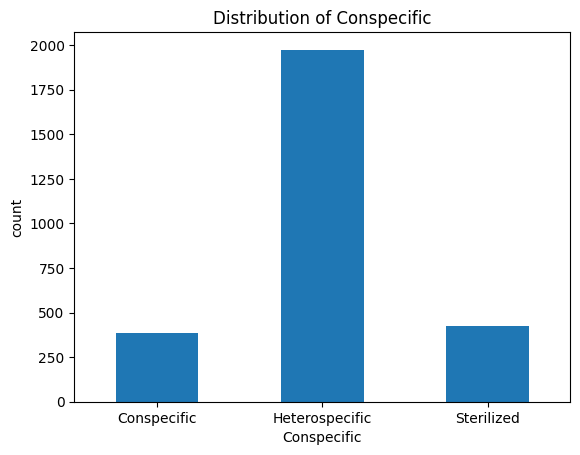

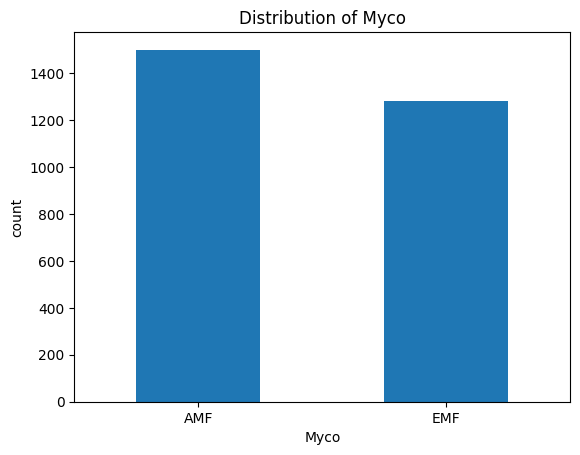

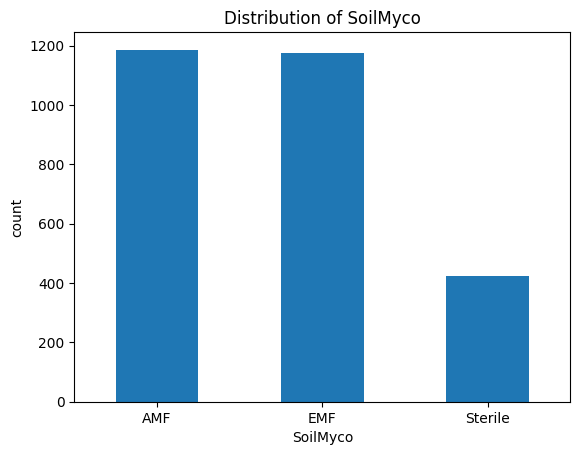

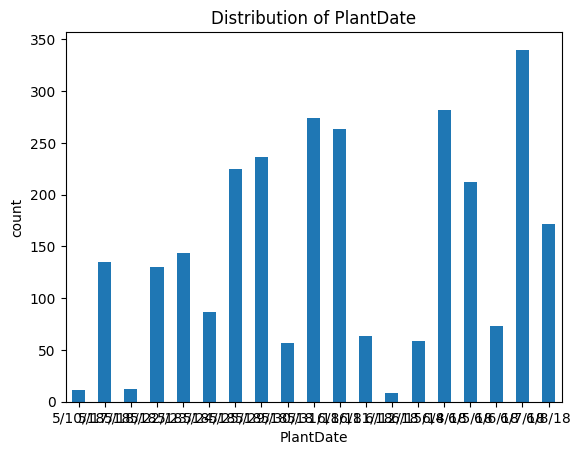

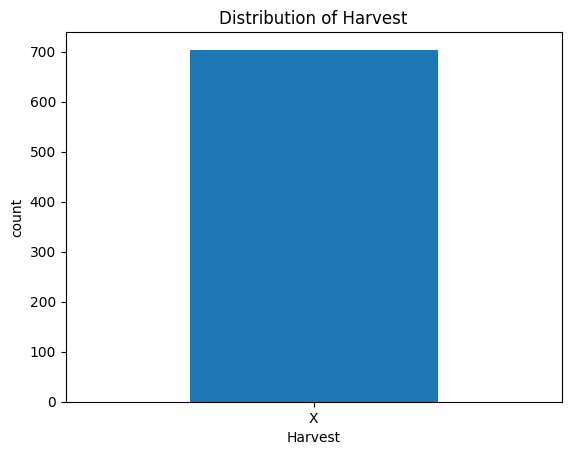

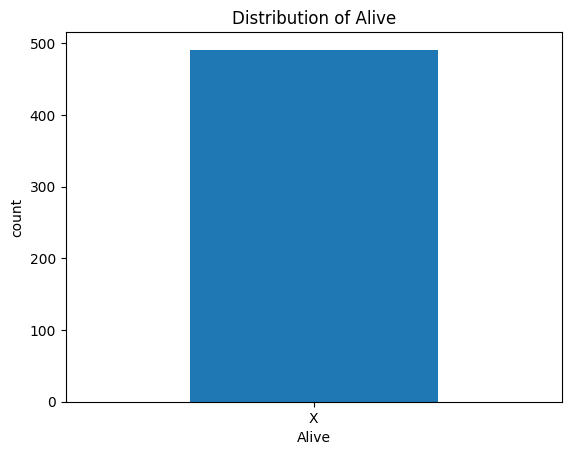

In [ ]:
# Barplot of unique value counts in every categorical features

unique_counts=categorical_data.nunique()
print(unique_counts)
for col in categorical:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

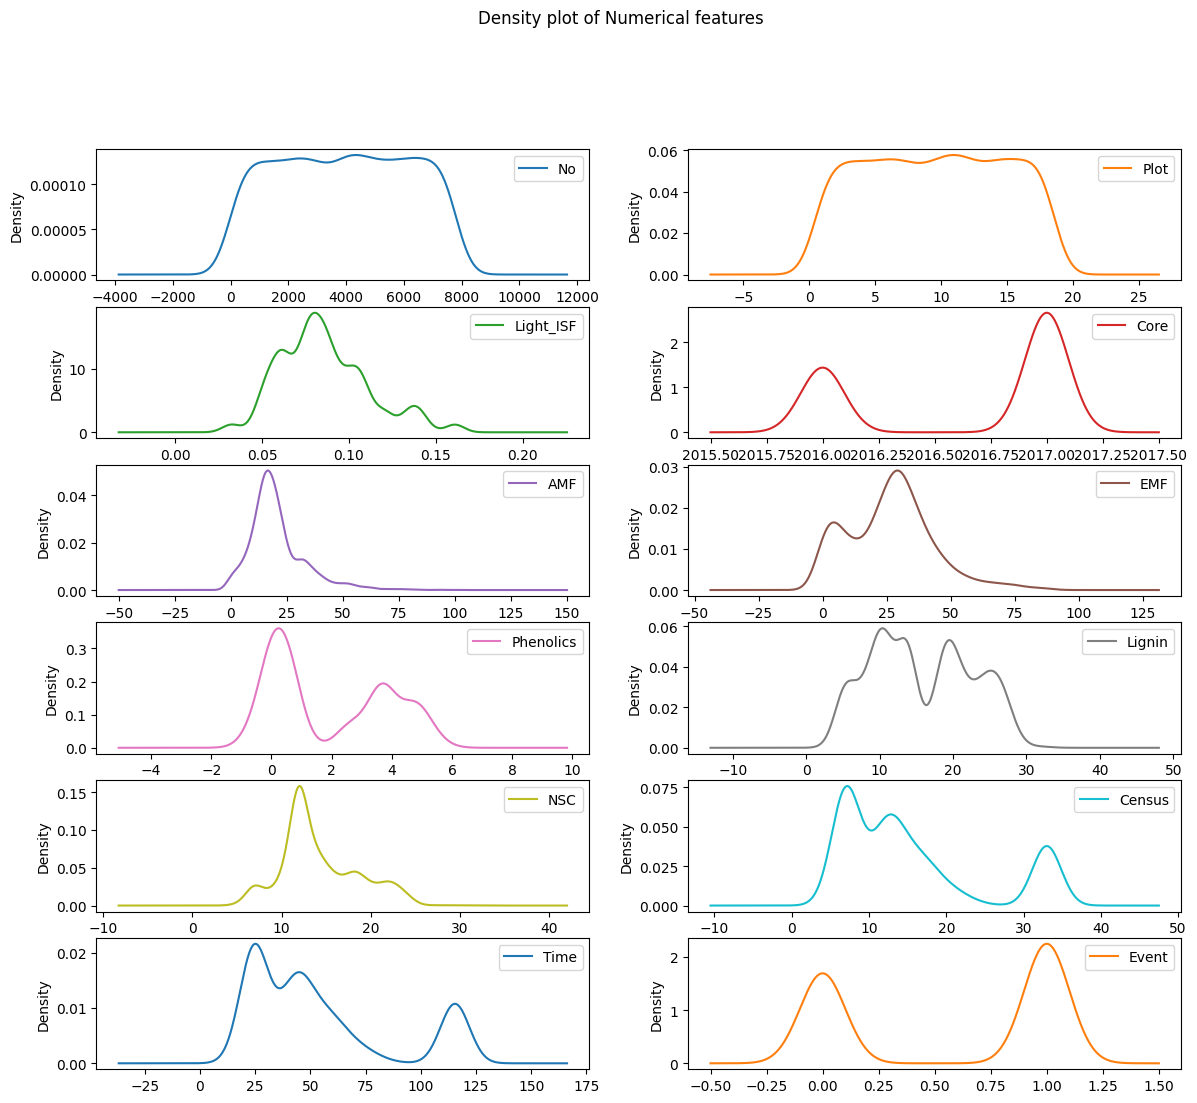

In [ ]:
numerical_data =df.select_dtypes(include='number')
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(7,2),title="Density plot of Numerical features",sharex=False)
plt.show()

In [ ]:
orrelation_matrix = numerical_data.corr()
correlation_matrix

,No,Plot,Light_ISF,Core,AMF,EMF,Phenolics,Lignin,NSC,Census,Time,Event
No,1.000000,0.998450,0.250086,0.040238,0.082042,0.164707,0.038217,-0.008797,0.026681,-0.062410,-0.062410,-0.070230
Plot,0.998450,1.000000,0.248232,0.037724,0.083960,0.164957,0.038924,-0.009677,0.027051,-0.061303,-0.061303,-0.070711
Light_ISF,0.250086,0.248232,1.000000,0.049650,0.099120,0.163202,0.098531,0.081305,0.227706,0.026203,0.026203,-0.048473
Core,0.040238,0.037724,0.049650,1.000000,-0.056579,-0.140301,0.051929,0.088418,0.054315,0.048183,0.048183,-0.052738
AMF,0.082042,0.083960,0.099120,-0.056579,1.000000,0.264975,-0.121295,-0.304034,-0.181600,-0.090019,-0.090019,0.134544
EMF,0.164707,0.164957,0.163202,-0.140301,0.264975,1.000000,0.359696,0.055293,0.117529,0.001533,0.001533,-0.037480
Phenolics,0.038217,0.038924,0.098531,0.051929,-0.121295,0.359696,1.000000,0.768149,0.791244,0.379782,0.379782,-0.575633
Lignin,-0.008797,-0.009677,0.081305,0.088418,-0.304034,0.055293,0.768149,1.000000,0.546625,0.293374,0.293374,-0.519645
NSC,0.026681,0.027051,0.227706,0.054315,-0.181600,0.117529,0.791244,0.546625,1.000000,0.368411,0.368411,-0.410076
Census,-0.062410,-0.061303,0.026203,0.048183,-0.090019,0.001533,0.379782,0.293374,0.368411,1.000000,1.000000,-0.232227


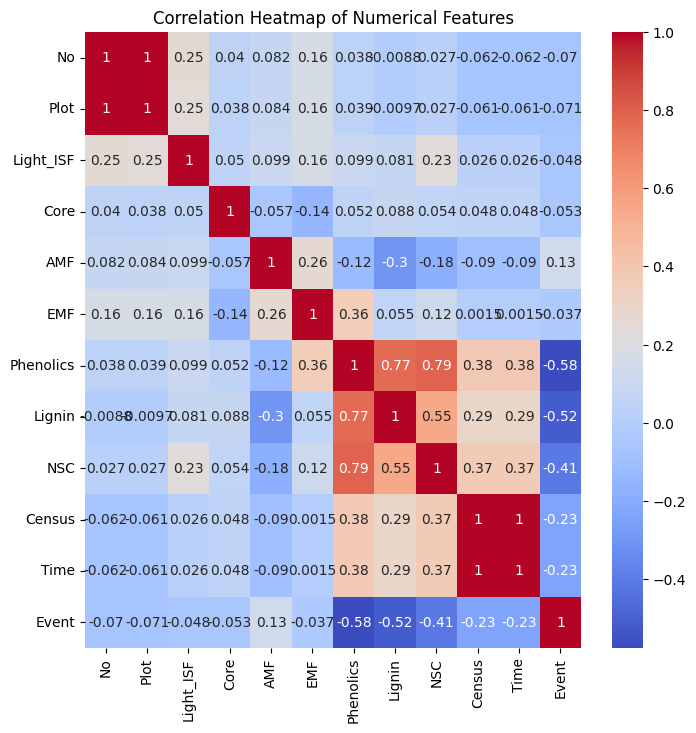

In [ ]:
# Calculate and visualize correlation matrix
plt.figure(figsize=(8, 8))
sns.heatmap(df[quantitative].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Features")
plt.show()


In [9]:
# Assuming your DataFrame is named df
# Drop duplicate columns based on their values

# Transpose the DataFrame to detect duplicate columns
duplicate_cols = df.T.duplicated()

# Filter and drop duplicates
df_cleaned = df.loc[:, ~duplicate_cols]

print("Dropped duplicate columns:")
print(df.columns[duplicate_cols].tolist())


Dropped duplicate columns:
[]


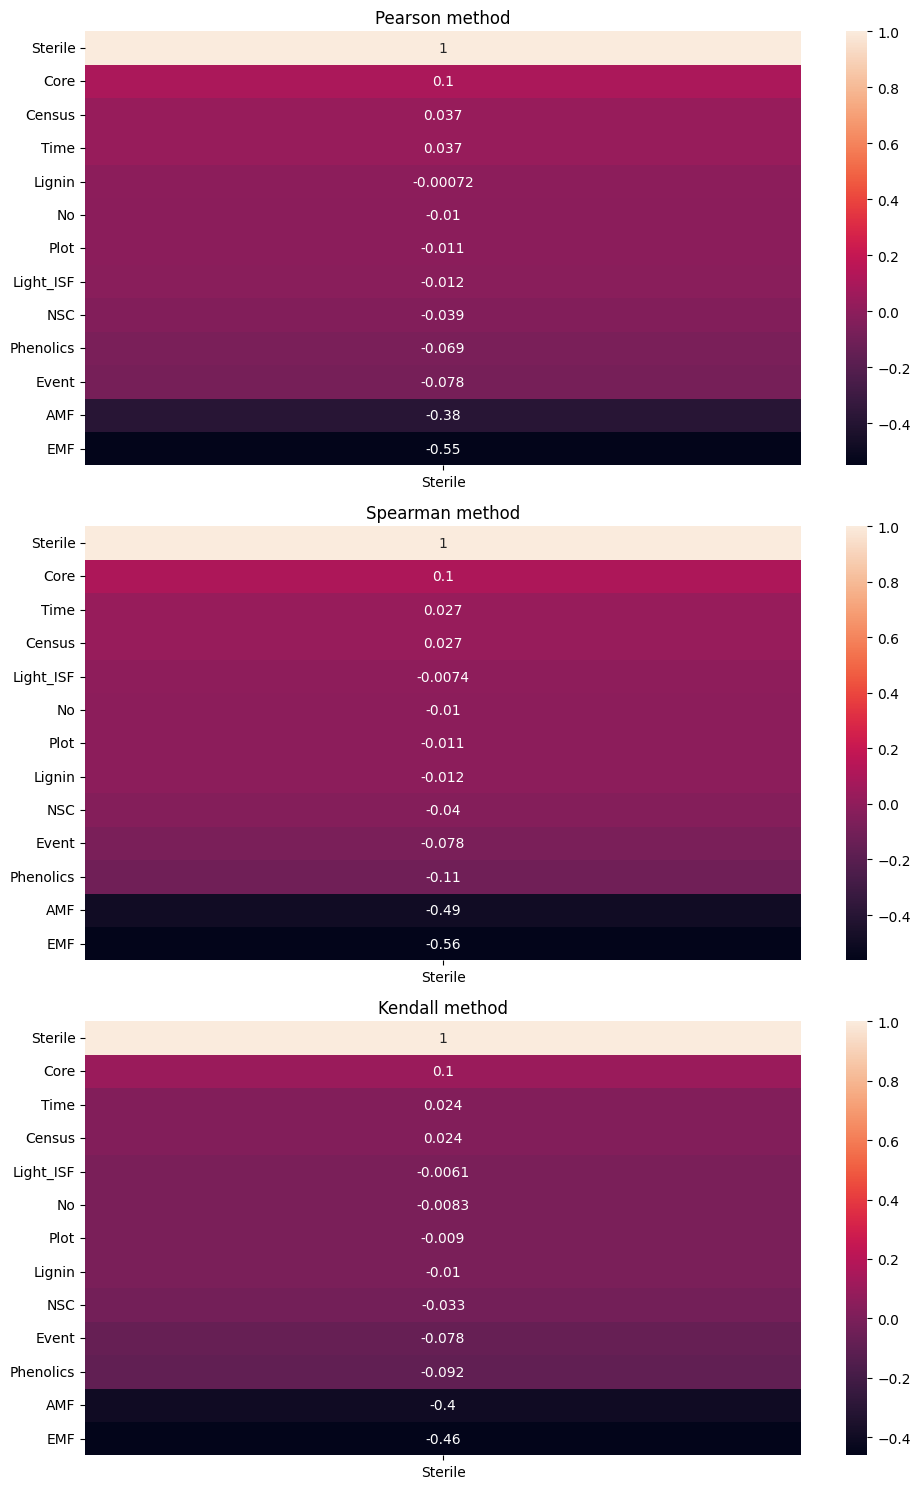

In [ ]:
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt

# Make a copy to avoid changing original data
numerical_data = df.copy()

# Encode 'Sterile' column
le = LabelEncoder()
numerical_data['Sterile'] = le.fit_transform(numerical_data['Sterile'])

# Keep only numeric columns
numerical_data = numerical_data.select_dtypes(include=['int64', 'float64'])

# Now calculate correlations
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

corr1 = numerical_data.corr('pearson')[['Sterile']].sort_values(by='Sterile', ascending=False)
corr2 = numerical_data.corr('spearman')[['Sterile']].sort_values(by='Sterile', ascending=False)
corr3 = numerical_data.corr('kendall')[['Sterile']].sort_values(by='Sterile', ascending=False)

# Set titles
ax[0].set_title('Pearson method')
ax[1].set_title('Spearman method')
ax[2].set_title('Kendall method')

# Plot heatmaps
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.tight_layout()
plt.show()

Exploratory Data Analysis (EDA)

**Dataset Pre-Processing**

Drop Unnecessary Columns

In [10]:
# Drop non-informative or irrelevant columns
columns_to_drop = ['No', 'Subplot', 'PlantDate', 'Harvest', 'Alive','Time']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

Handling Missing Values

In [19]:
# Impute missing values for numeric features using median
if 'EMF' in df.columns:
    df['EMF'] = df['EMF'].fillna(df['EMF'].median())

if 'Event' in df.columns:
    df['Event'] = df['Event'].fillna(df['Event'].median())

Encode the Target Variable (Sterile)

In [20]:
from sklearn.preprocessing import LabelEncoder

# Convert 'Sterile' from 'Yes'/'No' to 1/0
le = LabelEncoder()
df['Sterile'] = le.fit_transform(df['Sterile'])
print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

Class mapping: {'Non-Sterile': np.int64(0), 'Sterile': np.int64(1)}


In [21]:
categorical = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(categorical)

['Species', 'Light_Cat', 'Soil', 'Adult', 'Conspecific', 'Myco', 'SoilMyco']


Encode Categorical Input Features

In [22]:
# One-hot encode nominal categorical features
#categorical_cols = ['Species', 'Soil', 'Adult', 'Light_Cat', 'Conspecific', 'Myco', 'SoilMyco']
df = pd.get_dummies(df, columns=categorical, drop_first=True)

Feature Scaling (Standardization)

In [23]:
from sklearn.preprocessing import StandardScaler

# Separate features and target
x = df.drop(columns=['Sterile'])
y = df['Sterile']

# Select numeric columns only for scaling
numeric_cols = x.select_dtypes(include=['int64', 'float64']).columns

# Apply StandardScaler
scaler = StandardScaler()
x[numeric_cols] = scaler.fit_transform(x[numeric_cols])

Final Preprocessed Dataset

In [24]:
# Combine features and target for inspection
df_preprocessed = x.copy()
df_preprocessed['Sterile'] = y

# Final shape check
print("Final preprocessed dataset shape:", df_preprocessed.shape)
print(df_preprocessed.head())

Final preprocessed dataset shape: (2783, 62)
       Plot  Light_ISF      Core       AMF       EMF  Phenolics    Lignin  \
0 -1.645604   0.791680  0.735510  0.117566  0.050683  -1.265864 -0.280272   
1 -1.645604   0.791680  0.735510 -0.384572  0.346915   1.653676  0.702262   
2 -1.645604   0.791680  0.735510  0.316634  0.092244   0.724501  1.324829   
3 -0.492362  -0.222634 -1.359601  0.136254  0.050683  -1.342026 -0.216835   
4  0.853087  -1.002875  0.735510  0.048502  0.050683  -1.276019 -0.724330   

        NSC    Census     Event  ...  Adult_G  Adult_H  Adult_I  Adult_J  \
0 -0.481592 -1.231007  0.867478  ...    False    False     True    False   
1  1.179840  1.933236 -1.152766  ...    False    False    False    False   
2  0.183911  0.296558  0.867478  ...    False    False    False     True   
3 -0.432726 -1.231007  0.867478  ...    False    False    False     True   
4 -0.702651 -1.231007  0.867478  ...    False    False    False    False   

   Conspecific_Heterospecific  Cons

**Dataset Splitting**

In [25]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Separate features and target
x = df.drop(columns=['Sterile'])
y = df['Sterile']

# Apply SMOTE to balance the dataset
smote = SMOTE(random_state=42)
x_balanced, y_balanced = smote.fit_resample(x, y)

# Stratified train-test split
x_train, x_test, y_train, y_test = train_test_split(
    x_balanced, y_balanced,
    test_size=0.3,
    stratify=y_balanced,
    random_state=42
)

# Check class distribution after SMOTE
from collections import Counter
print("Class distribution after SMOTE (train + test combined):")
print(Counter(y_balanced))


Class distribution after SMOTE (train + test combined):
Counter({0: 2360, 1: 2360})


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(x_train)

X_train_scaled = scaler.transform(x_train)
X_test_scaled = scaler.transform(x_test)

**Model Training & Testing**

In [27]:
#Train and Evaluate Multiple Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(50,), max_iter=500, random_state=42)
}

# Loop to train and print results
for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    print(f"\n🔹 Model: {name}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification Report:\n", classification_report(
        y_test, y_pred, target_names=['Non-Sterile (0)', 'Sterile (1)']
    ))


🔹 Model: Logistic Regression
Accuracy: 1.0
Confusion Matrix:
 [[708   0]
 [  0 708]]
Classification Report:
                  precision    recall  f1-score   support

Non-Sterile (0)       1.00      1.00      1.00       708
    Sterile (1)       1.00      1.00      1.00       708

       accuracy                           1.00      1416
      macro avg       1.00      1.00      1.00      1416
   weighted avg       1.00      1.00      1.00      1416


🔹 Model: Random Forest
Accuracy: 1.0
Confusion Matrix:
 [[708   0]
 [  0 708]]
Classification Report:
                  precision    recall  f1-score   support

Non-Sterile (0)       1.00      1.00      1.00       708
    Sterile (1)       1.00      1.00      1.00       708

       accuracy                           1.00      1416
      macro avg       1.00      1.00      1.00      1416
   weighted avg       1.00      1.00      1.00      1416


🔹 Model: KNN (K=5)
Accuracy: 0.9675
Confusion Matrix:
 [[677  31]
 [ 15 693]]
Classification Re

**Model Selection or Comparision Analysis**

In [28]:
# Model Evaluation and Comparison
from sklearn.metrics import (
    f1_score, roc_auc_score, roc_curve, auc,
    classification_report, accuracy_score, precision_score, recall_score
)

# Lists to store evaluation results
model_names = []
f1_scores = []

# Re-train and evaluate models
for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    # Save name and F1 score for plotting
    model_names.append(name)
    f1 = f1_score(y_test, y_pred)
    f1_scores.append(f1)

    # Print full evaluation metrics
    print(f"\n🔹 Model: {name}")
    print("Accuracy      :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision     :", round(precision_score(y_test, y_pred), 4))
    print("Recall        :", round(recall_score(y_test, y_pred), 4))
    print("F1 Score      :", round(f1, 4))
    print("ROC AUC Score :", round(roc_auc_score(y_test, y_pred), 4))
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Non-Sterile', 'Sterile']))



🔹 Model: Logistic Regression
Accuracy      : 1.0
Precision     : 1.0
Recall        : 1.0
F1 Score      : 1.0
ROC AUC Score : 1.0

Classification Report:
               precision    recall  f1-score   support

 Non-Sterile       1.00      1.00      1.00       708
     Sterile       1.00      1.00      1.00       708

    accuracy                           1.00      1416
   macro avg       1.00      1.00      1.00      1416
weighted avg       1.00      1.00      1.00      1416


🔹 Model: Random Forest
Accuracy      : 1.0
Precision     : 1.0
Recall        : 1.0
F1 Score      : 1.0
ROC AUC Score : 1.0

Classification Report:
               precision    recall  f1-score   support

 Non-Sterile       1.00      1.00      1.00       708
     Sterile       1.00      1.00      1.00       708

    accuracy                           1.00      1416
   macro avg       1.00      1.00      1.00      1416
weighted avg       1.00      1.00      1.00      1416


🔹 Model: KNN (K=5)
Accuracy      : 0.9675

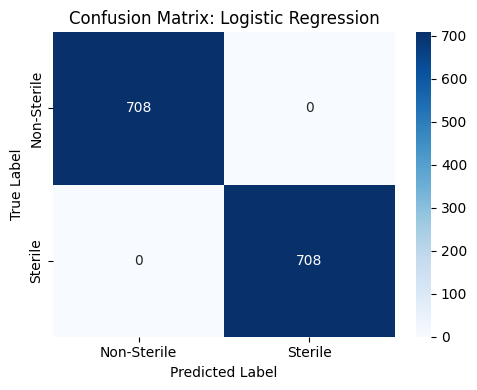

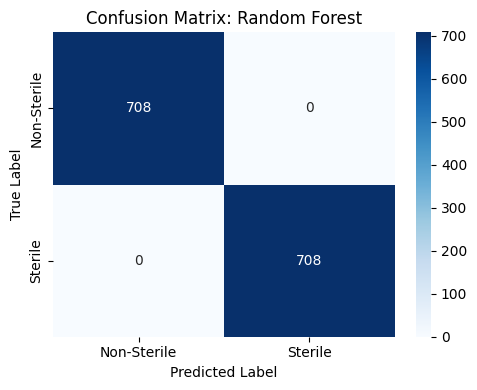

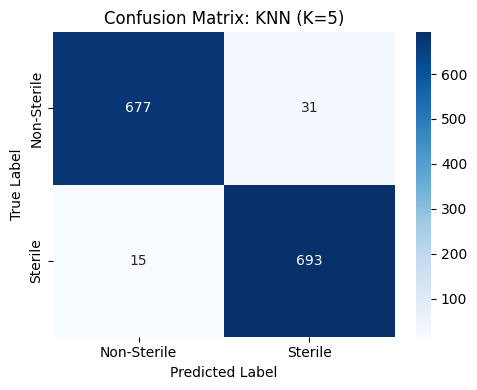

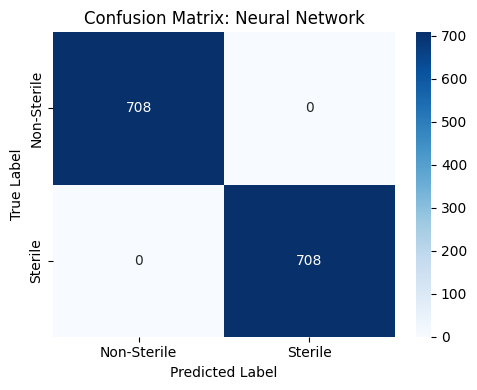

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Reuse the same models and predictions
for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Sterile', 'Sterile'], yticklabels=['Non-Sterile', 'Sterile'])
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()


Bar Chart: Model F1 Score Comparison

<ipython-input-30-2baca9de8576>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=f1_scores, palette='Set2')


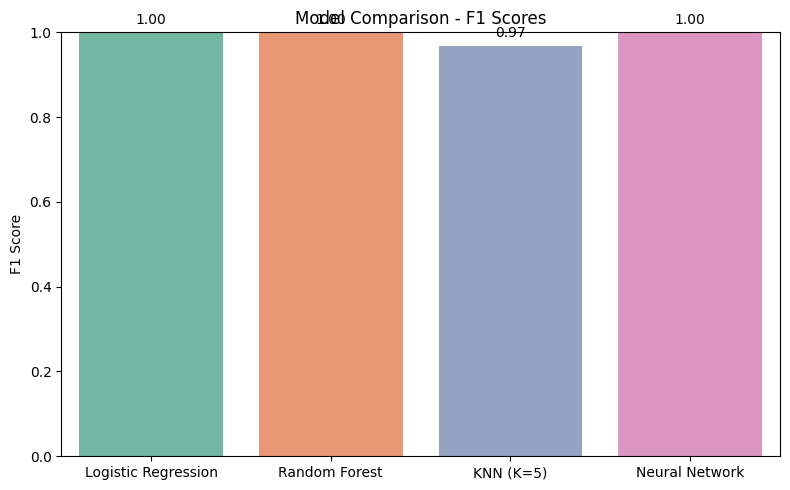

In [30]:
# Plot bar chart of F1 scores
plt.figure(figsize=(8, 5))
sns.barplot(x=model_names, y=f1_scores, palette='Set2')
plt.title('Model Comparison - F1 Scores')
plt.ylabel('F1 Score')
plt.ylim(0, 1)

# Add value labels above bars
for i, score in enumerate(f1_scores):
    plt.text(i, score + 0.02, f'{score:.2f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

ROC Curves for All Models

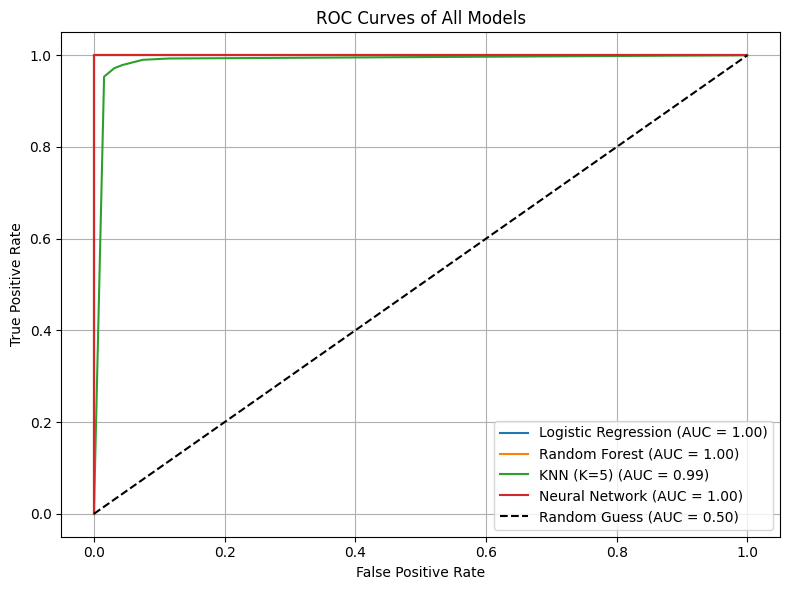

In [31]:
# Plot ROC curve for each model
plt.figure(figsize=(8, 6))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(x_test)[:, 1]
    else:
        y_scores = model.decision_function(x_test)

    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot random guess baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')

plt.title("ROC Curves of All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.grid()
plt.tight_layout()
plt.show()